In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('original - original.csv')

print("Dataset berhasil dibaca!")

Dataset berhasil dibaca!


In [6]:
# Menampilkan 5 baris pertama dataset
df.head()

,Gender,Age,POLAR4 Quintile,POLAR3 Quintile,Adult HE 2001 Quintile,Adult HE 2011 Quintile,TUNDRA MSOA Quintile,TUNDRA LSOA Quintile,Gaps GCSE Quintile,Gaps GCSE Ethnicity Quintile,Uni Connect target ward,attending from home?,distance to university (km),Count of Module Area Logins,Total Hours in Module Area,% of Average Hours in Module Area,# of presence,# of Absence,Percent Attended,"label (fail=1, pass=0)"
0,0,38,5,5,4,5,4,4,5,5,0,1,1.333.380.569,19,7.41,620.767.196,3,9.0,25,1
1,0,22,4,2,1,3,4,4,4,5,0,1,1.584.412.643,1,0.03,2.513.228,0,12.0,0,1
2,0,21,4,5,4,5,4,4,5,5,0,1,1.770.657.284,25,6.14,514.373.898,5,7.0,4.166.666.667,1
3,0,25,5,4,3,4,3,3,5,5,0,0,1.732.749.755,3,0.16,1.340.388,0,12.0,0,1
4,0,20,5,4,3,4,3,3,4,4,0,1,0,25,4.03,337.610.229,11,1.0,9.166.666.667,1


In [7]:
# Memeriksa dimensi dataset
print("Dimensi dataset:", df.shape)
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

Dimensi dataset: (80, 20)
Jumlah baris: 80
Jumlah kolom: 20


In [8]:
# Menampilkan informasi dan tipe data dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 20 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Gender                             80 non-null     int64  
 1   Age                                80 non-null     int64  
 2   POLAR4 Quintile                    80 non-null     int64  
 3   POLAR3 Quintile                    80 non-null     int64  
 4   Adult HE 2001 Quintile             80 non-null     int64  
 5   Adult HE 2011 Quintile             80 non-null     int64  
 6   TUNDRA MSOA Quintile               80 non-null     int64  
 7   TUNDRA LSOA Quintile               80 non-null     int64  
 8   Gaps GCSE Quintile                 80 non-null     int64  
 9   Gaps GCSE Ethnicity Quintile       80 non-null     int64  
 10  Uni Connect target ward            80 non-null     int64  
 11  attending from home?               80 non-null     int64  
 12  distanc

In [9]:
# Menampilkan jumlah mahasiswa lulus dan gagal
print("Distribusi Label:")
print(df['label (fail=1, pass=0)'].value_counts())

# Menampilkan persentase
print("\nPersentase Label:")
print(df['label (fail=1, pass=0)'].value_counts(normalize=True) * 100)

Distribusi Label:
label (fail=1, pass=0)
0    68
1    12
Name: count, dtype: int64

Persentase Label:
label (fail=1, pass=0)
0    85.0
1    15.0
Name: proportion, dtype: float64


### Interpretasi Data Understanding

Dataset ini digunakan untuk memprediksi kegagalan mahasiswa pada suatu modul perkuliahan. Dataset terdiri dari 80 data mahasiswa dengan 19 fitur dan 1 kolom target.

Fitur dalam dataset dikelompokkan menjadi:

1. **Demografi:** jenis kelamin (Gender) dan usia (Age).
2. **Latar belakang wilayah:** indikator POLAR, Adult HE, TUNDRA, Gaps GCSE, dan Uni Connect.
3. **Keterlibatan pembelajaran:** status tinggal di rumah, jarak ke kampus, jumlah login modul, dan durasi belajar online.
4. **Kehadiran:** jumlah kehadiran, jumlah ketidakhadiran, dan persentase kehadiran.

Kolom target adalah `label (fail=1, pass=0)`, dengan nilai 0 berarti mahasiswa lulus dan nilai 1 berarti mahasiswa gagal.

Berdasarkan analisis distribusi label, terdapat 68 mahasiswa lulus (85%) dan 12 mahasiswa gagal (15%). Kondisi ini menunjukkan ketidakseimbangan kelas (*class imbalance*).

Oleh karena itu, evaluasi model tidak cukup hanya menggunakan akurasi, tetapi juga perlu mempertimbangkan precision, recall, F1-score, dan confusion matrix, khususnya untuk mengukur kemampuan model dalam mendeteksi mahasiswa yang gagal.

In [10]:
# Memeriksa kualitas dataset

print("Jumlah baris kosong seluruhnya:")
print(df.isna().all(axis=1).sum())

print("\nJumlah kolom kosong seluruhnya:")
print(df.isna().all(axis=0).sum())

print("\nJumlah nilai hilang setiap kolom:")
print(df.isna().sum())

print("\nJumlah baris duplikat:")
print(df.duplicated().sum())

Jumlah baris kosong seluruhnya:
0

Jumlah kolom kosong seluruhnya:
0

Jumlah nilai hilang setiap kolom:
Gender                               0
Age                                  0
POLAR4 Quintile                      0
POLAR3 Quintile                      0
Adult HE 2001 Quintile               0
Adult HE 2011 Quintile               0
TUNDRA MSOA Quintile                 0
TUNDRA LSOA Quintile                 0
Gaps GCSE Quintile                   0
Gaps GCSE Ethnicity Quintile         0
Uni Connect target ward              0
attending from home?                 0
distance to university (km)          0
Count of Module Area Logins          0
Total Hours in Module Area           0
% of Average Hours in Module Area    0
# of presence                        0
# of Absence                         2
Percent Attended                     0
label (fail=1, pass=0)               0
dtype: int64

Jumlah baris duplikat:
0


In [11]:
# Menampilkan data yang memiliki nilai kosong
df[df['# of Absence'].isna()]

,Gender,Age,POLAR4 Quintile,POLAR3 Quintile,Adult HE 2001 Quintile,Adult HE 2011 Quintile,TUNDRA MSOA Quintile,TUNDRA LSOA Quintile,Gaps GCSE Quintile,Gaps GCSE Ethnicity Quintile,Uni Connect target ward,attending from home?,distance to university (km),Count of Module Area Logins,Total Hours in Module Area,% of Average Hours in Module Area,# of presence,# of Absence,Percent Attended,"label (fail=1, pass=0)"
16,0,24,2,2,1,3,1,1,3,4,0,1,1.420.329.549,38,13.26,1.015.080.762,9,NaN,100,0
20,0,22,4,4,3,4,4,4,4,5,0,1,2.520.825.881,72,19.56,1.497.358.953,9,NaN,100,0


In [12]:
# Memeriksa data kehadiran mahasiswa
kolom = [
    '# of presence',
    '# of Absence',
    'Percent Attended'
]

print(df.loc[[16, 20], kolom])

print("\nContoh data mahasiswa lainnya:")
print(df.loc[0:5, kolom])

    # of presence  # of Absence Percent Attended
16              9           NaN              100
20              9           NaN              100

Contoh data mahasiswa lainnya:
   # of presence  # of Absence Percent Attended
0              3           9.0               25
1              0          12.0                0
2              5           7.0    4.166.666.667
3              0          12.0                0
4             11           1.0    9.166.666.667
5              9           3.0               75


In [13]:
# Memeriksa total pertemuan mahasiswa
data_hadir = df.dropna(subset=['# of Absence']).copy()

data_hadir['Total Pertemuan'] = (
    data_hadir['# of presence'] +
    data_hadir['# of Absence']
)

print("Distribusi total pertemuan:")
print(data_hadir['Total Pertemuan'].value_counts().sort_index())

print("\nData dengan total pertemuan bukan 12:")
print(
    data_hadir.loc[
        data_hadir['Total Pertemuan'] != 12,
        ['# of presence', '# of Absence', 'Percent Attended']
    ]
)

Distribusi total pertemuan:
Total Pertemuan
9.0      7
10.0     2
11.0     6
12.0    61
13.0     2
Name: count, dtype: int64

Data dengan total pertemuan bukan 12:
    # of presence  # of Absence Percent Attended
7               9           2.0               75
10              7           4.0    5.833.333.333
12              8           1.0            88.89
13              8           1.0            88.89
14              3           6.0            33.33
15              8           1.0            88.89
17              6           3.0            66.67
18              3           6.0            33.33
19              6           3.0            66.67
31              5           6.0    4.166.666.667
35              6           5.0               50
44             10           0.0    8.333.333.333
55              5           5.0    4.166.666.667
64             13           0.0              100
71              9           2.0               75
72             13           0.0              100
74 

In [14]:
# Memeriksa nilai asli pada tiga kolom
kolom_teks = [
    'distance to university (km)',
    '% of Average Hours in Module Area',
    'Percent Attended'
]

for kolom in kolom_teks:
    print("\nKolom:", kolom)
    print(df[kolom].head(10).tolist())


Kolom: distance to university (km)
['1.333.380.569', '1.584.412.643', '1.770.657.284', '1.732.749.755', '0', '3.528.856.173', '2.358.863.612', '3.259.523.336', '3.389.493.679', '3.173.273.631']

Kolom: % of Average Hours in Module Area
['620.767.196', '2.513.228', '514.373.898', '1.340.388', '337.610.229', '523.126.065', '342.075.404', '585.247.286', '754.445.872', '97.309.622']

Kolom: Percent Attended
['25', '0', '4.166.666.667', '0', '9.166.666.667', '75', '50', '75', '8.333.333.333', '75']


In [15]:
# Memeriksa isi asli file CSV
with open('original - original.csv', 'r', encoding='utf-8-sig') as file:
    for i in range(6):
        print(repr(file.readline()))

'Gender,Age,POLAR4 Quintile,POLAR3 Quintile,Adult HE 2001 Quintile,Adult HE 2011 Quintile,TUNDRA MSOA Quintile,TUNDRA LSOA Quintile,Gaps GCSE Quintile,Gaps GCSE Ethnicity Quintile,Uni Connect target ward,attending from home?,distance to university (km),Count of Module Area Logins,Total Hours in Module Area,% of Average Hours in Module Area,# of presence,# of Absence,Percent Attended,"label (fail=1, pass=0)"\n'
'0,38,5,5,4,5,4,4,5,5,0,1,1.333.380.569,19,7.41,620.767.196,3,9,25,1\n'
'0,22,4,2,1,3,4,4,4,5,0,1,1.584.412.643,1,0.03,2.513.228,0,12,0,1\n'
'0,21,4,5,4,5,4,4,5,5,0,1,1.770.657.284,25,6.14,514.373.898,5,7,4.166.666.667,1\n'
'0,25,5,4,3,4,3,3,5,5,0,0,1.732.749.755,3,0.16,1.340.388,0,12,0,1\n'
'0,20,5,4,3,4,3,3,4,4,0,1,0,25,04.03,337.610.229,11,1,9.166.666.667,1\n'


In [16]:
# Memeriksa pola angka pada kolom bermasalah
kolom_bermasalah = [
    'distance to university (km)',
    '% of Average Hours in Module Area',
    'Percent Attended'
]

for kolom in kolom_bermasalah:
    print("\nKOLOM:", kolom)

    nilai = df[kolom].astype(str)

    print("Jumlah titik dalam nilai:")
    print(nilai.str.count(r'\.').value_counts().sort_index())

    print("\nContoh nilai dengan lebih dari satu titik:")
    print(nilai[nilai.str.count(r'\.') > 1].head(10).tolist())


KOLOM: distance to university (km)
Jumlah titik dalam nilai:
distance to university (km)
0    17
2     1
3    62
Name: count, dtype: int64

Contoh nilai dengan lebih dari satu titik:
['1.333.380.569', '1.584.412.643', '1.770.657.284', '1.732.749.755', '3.528.856.173', '2.358.863.612', '3.259.523.336', '3.389.493.679', '3.173.273.631', '1.770.657.284']

KOLOM: % of Average Hours in Module Area
Jumlah titik dalam nilai:
% of Average Hours in Module Area
2    50
3    30
Name: count, dtype: int64

Contoh nilai dengan lebih dari satu titik:
['620.767.196', '2.513.228', '514.373.898', '1.340.388', '337.610.229', '523.126.065', '342.075.404', '585.247.286', '754.445.872', '97.309.622']

KOLOM: Percent Attended
Jumlah titik dalam nilai:
Percent Attended
0    36
1     7
3    37
Name: count, dtype: int64

Contoh nilai dengan lebih dari satu titik:
['4.166.666.667', '9.166.666.667', '8.333.333.333', '5.833.333.333', '3.333.333.333', '3.333.333.333', '8.333.333.333', '6.666.666.667', '8.333.333.3

In [17]:
# Memeriksa hubungan jam belajar dan rasio jam belajar

print(df[[
    'Total Hours in Module Area',
    '% of Average Hours in Module Area'
]].head(20).to_string())

    Total Hours in Module Area % of Average Hours in Module Area
0                         7.41                       620.767.196
1                         0.03                         2.513.228
2                         6.14                       514.373.898
3                         0.16                         1.340.388
4                         4.03                       337.610.229
5                        12.80                       523.126.065
6                         8.37                       342.075.404
7                        14.32                       585.247.286
8                        18.46                       754.445.872
9                        23.81                        97.309.622
10                        6.47                       264.423.878
11                        6.28                       256.658.726
12                       24.25                     1.856.388.272
13                       12.51                       957.666.692
14                       

In [18]:
# Membuat salinan dataset
df_clean = df.copy()

# Memperbaiki format jarak
def bersihkan_jarak(x):
    angka = str(x).replace('.', '')
    if angka == '0':
        return 0.0
    return int(angka) / 100000000

df_clean['distance to university (km)'] = (
    df_clean['distance to university (km)'].apply(bersihkan_jarak)
)

# Memperbaiki persentase kehadiran
def bersihkan_persen(x):
    teks = str(x)
    if teks.count('.') > 1:
        return int(teks.replace('.', '')) / 100000000
    return float(teks)

df_clean['Percent Attended'] = (
    df_clean['Percent Attended'].apply(bersihkan_persen)
)

# Mengisi nilai ketidakhadiran yang kosong
df_clean['# of Absence'] = (
    df_clean['# of Absence'].fillna(0)
)

print("Pembersihan awal selesai!")
print(df_clean.isna().sum().sum())

Pembersihan awal selesai!
0


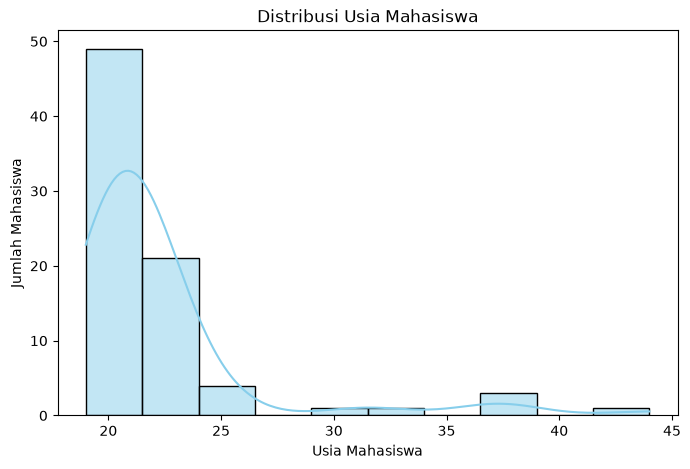

In [19]:
# EDA 1: Histogram distribusi usia mahasiswa

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x='Age',
    bins=10,
    kde=True,
    color='skyblue'
)

plt.title('Distribusi Usia Mahasiswa')
plt.xlabel('Usia Mahasiswa')
plt.ylabel('Jumlah Mahasiswa')
plt.show()

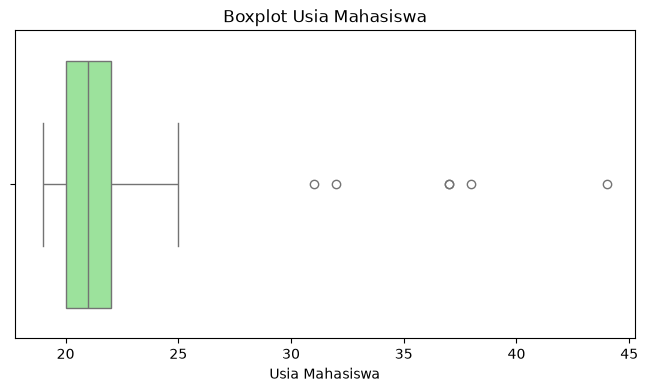

In [20]:
# EDA 2: Boxplot usia mahasiswa

plt.figure(figsize=(8, 4))

sns.boxplot(
    x=df_clean['Age'],
    color='lightgreen'
)

plt.title('Boxplot Usia Mahasiswa')
plt.xlabel('Usia Mahasiswa')
plt.show()

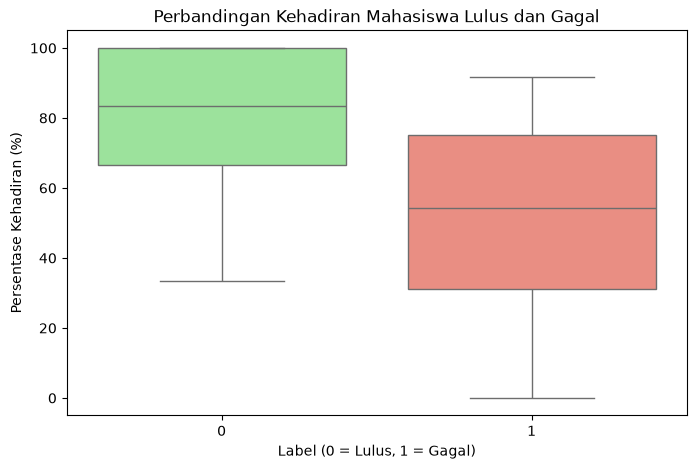

In [21]:
# EDA 3: Perbandingan kehadiran berdasarkan label

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x='label (fail=1, pass=0)',
    y='Percent Attended',
    hue='label (fail=1, pass=0)',
    palette=['lightgreen', 'salmon'],
    legend=False
)

plt.title('Perbandingan Kehadiran Mahasiswa Lulus dan Gagal')
plt.xlabel('Label (0 = Lulus, 1 = Gagal)')
plt.ylabel('Persentase Kehadiran (%)')
plt.show()

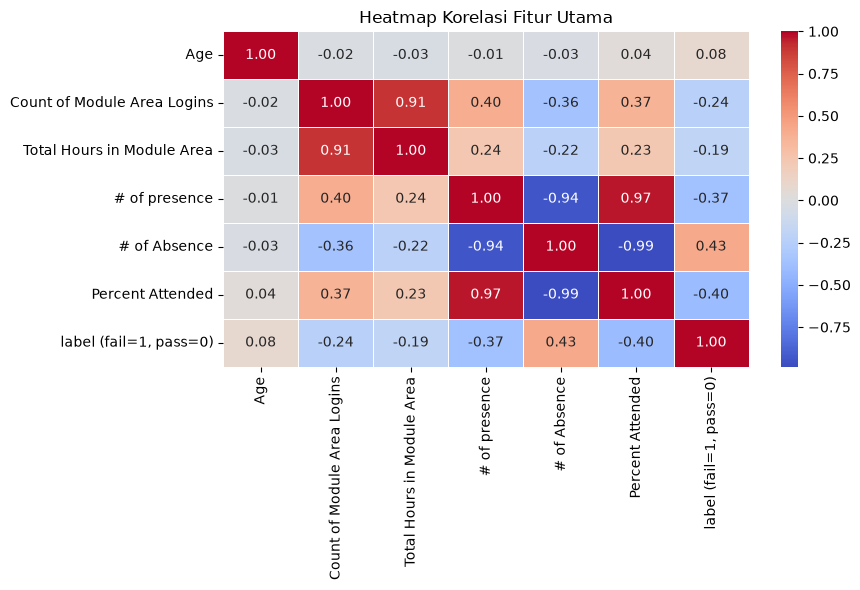

In [22]:
# EDA 4: Heatmap korelasi fitur utama

fitur_utama = [
    'Age',
    'Count of Module Area Logins',
    'Total Hours in Module Area',
    '# of presence',
    '# of Absence',
    'Percent Attended',
    'label (fail=1, pass=0)'
]

plt.figure(figsize=(9, 6))

sns.heatmap(
    df_clean[fitur_utama].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Heatmap Korelasi Fitur Utama')
plt.tight_layout()
plt.show()

In [23]:
# Deteksi outlier menggunakan metode IQR

kolom = ['Age', 'Count of Module Area Logins',
         'Total Hours in Module Area']

for fitur in kolom:
    Q1 = df_clean[fitur].quantile(0.25)
    Q3 = df_clean[fitur].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    outlier = df_clean[
        (df_clean[fitur] < batas_bawah) |
        (df_clean[fitur] > batas_atas)
    ]

    print(f"{fitur}: {len(outlier)} outlier")

Age: 6 outlier
Count of Module Area Logins: 2 outlier
Total Hours in Module Area: 3 outlier


In [24]:
# Menyiapkan dataset untuk modeling
df_model = df_clean.drop(
    columns=['% of Average Hours in Module Area']
).copy()

# Mengembalikan nilai kosong asli untuk imputasi nanti
df_model['# of Absence'] = df['# of Absence']

print("Ukuran data:", df_model.shape)
print("Nilai kosong:", df_model.isna().sum().sum())

Ukuran data: (80, 19)
Nilai kosong: 2


In [25]:
# Memilih fitur dan label

target = 'label (fail=1, pass=0)'

fitur_dihapus = [
    target,
    'TUNDRA LSOA Quintile',
    '# of presence',
    '# of Absence'
]

X = df_model.drop(columns=fitur_dihapus)
y = df_model[target]

print("Jumlah fitur:", X.shape[1])
print("Jumlah data:", X.shape[0])
print("Distribusi label:")
print(y.value_counts())

Jumlah fitur: 15
Jumlah data: 80
Distribusi label:
label (fail=1, pass=0)
0    68
1    12
Name: count, dtype: int64


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Data latih:", X_train.shape)
print("Data uji:", X_test.shape)

print("\nDistribusi label data latih:")
print(y_train.value_counts())

print("\nDistribusi label data uji:")
print(y_test.value_counts())

Data latih: (64, 15)
Data uji: (16, 15)

Distribusi label data latih:
label (fail=1, pass=0)
0    54
1    10
Name: count, dtype: int64

Distribusi label data uji:
label (fail=1, pass=0)
0    14
1     2
Name: count, dtype: int64


In [27]:
# Mengeluarkan fitur jarak yang belum tervalidasi
X_train = X_train.drop(
    columns=['distance to university (km)']
)

X_test = X_test.drop(
    columns=['distance to university (km)']
)

print("Data latih:", X_train.shape)
print("Data uji:", X_test.shape)
print("Nilai kosong:", X_train.isna().sum().sum())

Data latih: (64, 14)
Data uji: (16, 14)
Nilai kosong: 0


### 3.4 Normalisasi Data (StandardScaler)

Pada tahap ini dilakukan standardisasi fitur menggunakan StandardScaler agar fitur dengan nilai besar tidak mendominasi fitur lainnya. Proses standardisasi dilakukan berdasarkan data latih, kemudian diterapkan pada data uji untuk menghindari data leakage.

In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling berhasil!")
print("Data latih:", X_train_scaled.shape)
print("Data uji:", X_test_scaled.shape)

Scaling berhasil!
Data latih: (64, 14)
Data uji: (16, 14)


### 4.1 Modeling Menggunakan Logistic Regression

Logistic Regression digunakan sebagai model klasifikasi pertama untuk memprediksi mahasiswa lulus atau gagal berdasarkan fitur yang telah dipilih.

Algoritma ini dipilih karena cocok untuk klasifikasi biner, cukup sederhana, dan dapat menghasilkan probabilitas prediksi. Model menggunakan `class_weight='balanced'` untuk membantu menangani ketidakseimbangan jumlah mahasiswa lulus dan gagal.

In [29]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)

model_lr.fit(X_train_scaled, y_train)

print("Model Logistic Regression berhasil dilatih!")

Model Logistic Regression berhasil dilatih!


### 4.2 Modeling Menggunakan Random Forest

Random Forest digunakan sebagai algoritma klasifikasi kedua untuk memprediksi kelulusan mahasiswa.

Algoritma ini dipilih karena mampu mempelajari hubungan yang lebih kompleks antarfitur dengan menggabungkan beberapa Decision Tree. Random Forest juga dapat membantu mengetahui fitur yang berpengaruh terhadap hasil prediksi.

Parameter `class_weight='balanced'` digunakan untuk membantu menangani ketidakseimbangan kelas pada dataset.

In [30]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)

model_rf.fit(X_train, y_train)

print("Model Random Forest berhasil dilatih!")

Model Random Forest berhasil dilatih!


### 4.3 Cross-Validation dan Perbandingan Model

Cross-validation digunakan untuk mengevaluasi kemampuan model dengan membagi data latih menjadi lima bagian secara bergantian.

Saya menggunakan Stratified 5-Fold agar proporsi mahasiswa lulus dan gagal tetap terjaga pada setiap pembagian data.

Metrik yang digunakan adalah F1-score untuk kelas gagal (1), karena dataset memiliki jumlah mahasiswa gagal yang lebih sedikit dibandingkan mahasiswa lulus.

In [31]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

lr_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    )
)

rf_pipeline = make_pipeline(
    RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42
    )
)

skor_lr = cross_val_score(
    lr_pipeline, X_train, y_train,
    cv=cv, scoring='f1'
)

skor_rf = cross_val_score(
    rf_pipeline, X_train, y_train,
    cv=cv, scoring='f1'
)

print("F1 Logistic Regression:", skor_lr.mean())
print("F1 Random Forest:", skor_rf.mean())

F1 Logistic Regression: 0.45999999999999996
F1 Random Forest: 0.44000000000000006


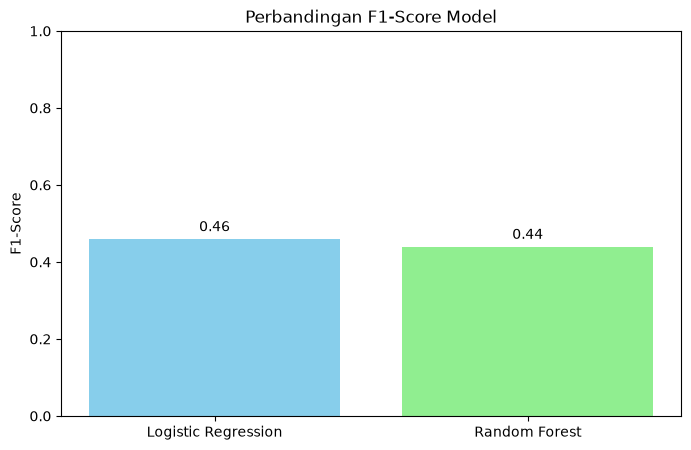

In [32]:
# Visualisasi perbandingan hasil modeling

model = ['Logistic Regression', 'Random Forest']
f1_score = [skor_lr.mean(), skor_rf.mean()]

plt.figure(figsize=(8, 5))
plt.bar(model, f1_score, color=['skyblue', 'lightgreen'])

plt.title('Perbandingan F1-Score Model')
plt.ylabel('F1-Score')
plt.ylim(0, 1)

for i, nilai in enumerate(f1_score):
    plt.text(i, nilai + 0.02, f'{nilai:.2f}',
             ha='center')

plt.show()

### Interpretasi Hasil Modeling

Berdasarkan hasil cross-validation, Logistic Regression memperoleh rata-rata F1-score sebesar 0,46, sedangkan Random Forest memperoleh 0,44.

Hasil ini menunjukkan bahwa Logistic Regression memiliki performa sedikit lebih baik dalam menyeimbangkan precision dan recall untuk memprediksi mahasiswa yang gagal.

Oleh karena itu, Logistic Regression dipilih sebagai model terbaik sementara untuk dilanjutkan ke tahap evaluasi menggunakan data uji.

### 5.1 Evaluasi Model Logistic Regression

Pada tahap ini, model Logistic Regression dievaluasi menggunakan data uji sebanyak 16 mahasiswa. Evaluasi dilakukan untuk mengetahui kemampuan model dalam memprediksi mahasiswa lulus (0) atau gagal (1).

Metrik yang digunakan adalah accuracy, precision, recall, dan F1-score. Karena jumlah mahasiswa gagal lebih sedikit, precision, recall, dan F1-score untuk kelas gagal menjadi perhatian utama.

In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Prediksi menggunakan data uji
y_pred_lr = model_lr.predict(X_test_scaled)

# Menghitung metrik evaluasi
print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred_lr, zero_division=0))
print("F1-Score :", f1_score(y_test, y_pred_lr, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Accuracy : 0.6875
Precision: 0.2
Recall   : 0.5
F1-Score : 0.2857142857142857

Confusion Matrix:
[[10  4]
 [ 1  1]]


### 5.2 Visualisasi Confusion Matrix

Confusion matrix digunakan untuk melihat jumlah prediksi benar dan salah yang dihasilkan model Logistic Regression pada data uji. Visualisasi ini membantu mengetahui kemampuan model dalam membedakan mahasiswa lulus dan gagal.

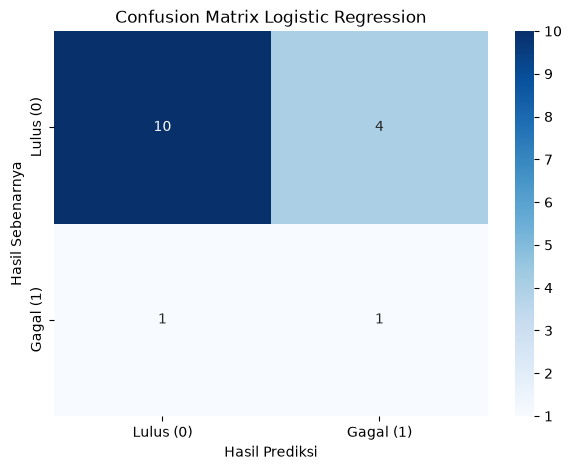

In [34]:
# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Lulus (0)', 'Gagal (1)'],
    yticklabels=['Lulus (0)', 'Gagal (1)']
)

plt.title('Confusion Matrix Logistic Regression')
plt.xlabel('Hasil Prediksi')
plt.ylabel('Hasil Sebenarnya')
plt.show()

### Interpretasi Confusion Matrix

Berdasarkan hasil evaluasi terhadap 16 data mahasiswa, model berhasil memprediksi 10 mahasiswa lulus dan 1 mahasiswa gagal dengan benar.

Namun, terdapat 4 mahasiswa yang sebenarnya lulus tetapi diprediksi gagal, serta 1 mahasiswa yang sebenarnya gagal tetapi diprediksi lulus.

Nilai accuracy sebesar 68,75% menunjukkan bahwa model mampu memprediksi sebagian besar data dengan benar. Akan tetapi, F1-score sebesar 28,57% menunjukkan bahwa kemampuan model dalam mengenali mahasiswa gagal masih perlu ditingkatkan.

Hasil evaluasi juga perlu diperhatikan karena jumlah mahasiswa gagal pada data uji hanya 2 orang.

### 5.3 Analisis Fitur Paling Berpengaruh

Pada tahap ini dilakukan analisis koefisien Logistic Regression untuk mengetahui fitur yang paling berpengaruh terhadap prediksi kelulusan mahasiswa.

Nilai absolut koefisien digunakan untuk membandingkan besarnya pengaruh setiap fitur. Koefisien positif menunjukkan kecenderungan peningkatan prediksi gagal (1), sedangkan koefisien negatif menunjukkan kecenderungan prediksi lulus (0).

In [35]:
# Menghitung pengaruh fitur Logistic Regression
fitur_penting = pd.DataFrame({
    'Fitur': X_train.columns,
    'Koefisien': model_lr.coef_[0]
})

fitur_penting['Pengaruh'] = fitur_penting['Koefisien'].abs()

fitur_penting = fitur_penting.sort_values(
    by='Pengaruh',
    ascending=False
)

print("10 Fitur Paling Berpengaruh:")
display(fitur_penting.head(10))

10 Fitur Paling Berpengaruh:


,Fitur,Koefisien,Pengaruh
13,Percent Attended,-1.098713,1.098713
2,POLAR4 Quintile,0.994007,0.994007
10,attending from home?,0.993174,0.993174
0,Gender,-0.928285,0.928285
4,Adult HE 2001 Quintile,-0.809496,0.809496
12,Total Hours in Module Area,-0.787823,0.787823
7,Gaps GCSE Quintile,0.763877,0.763877
11,Count of Module Area Logins,-0.746988,0.746988
9,Uni Connect target ward,-0.469017,0.469017
5,Adult HE 2011 Quintile,0.344867,0.344867


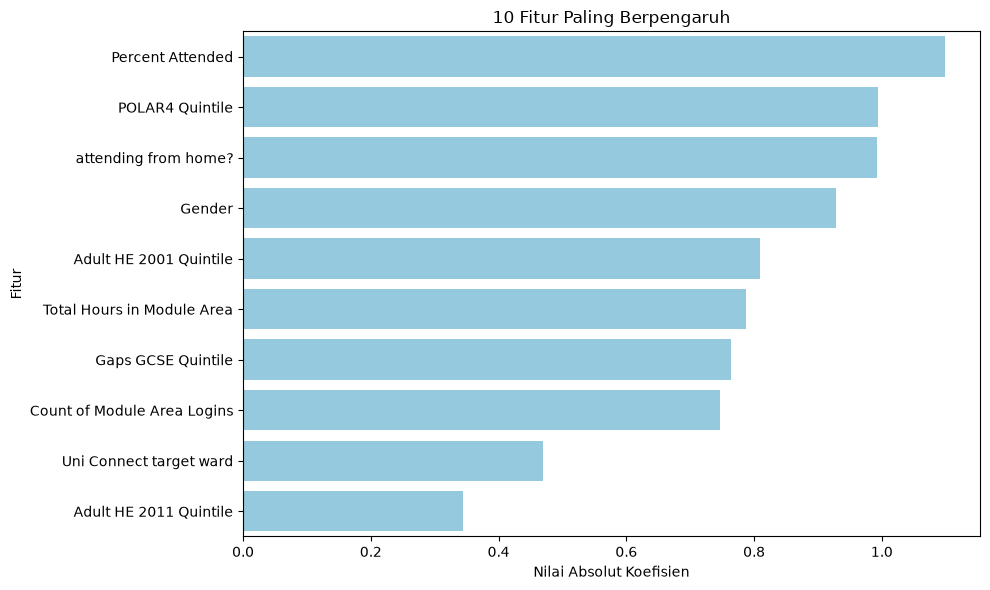

In [36]:
# Grafik 10 fitur paling berpengaruh

plt.figure(figsize=(10, 6))

sns.barplot(
    data=fitur_penting.head(10),
    x='Pengaruh',
    y='Fitur',
    color='skyblue'
)

plt.title('10 Fitur Paling Berpengaruh')
plt.xlabel('Nilai Absolut Koefisien')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

### Interpretasi Fitur Paling Berpengaruh

Berdasarkan hasil analisis koefisien Logistic Regression, tiga fitur dengan nilai absolut koefisien terbesar adalah Percent Attended (1,099), POLAR4 Quintile (0,994), dan attending from home? (0,993).

Persentase kehadiran memiliki koefisien negatif, sehingga peningkatan kehadiran berkaitan dengan penurunan kecenderungan prediksi gagal. Sementara itu, POLAR4 Quintile dan attending from home? memiliki koefisien positif.

Hasil ini menunjukkan hubungan yang dipelajari model, bukan hubungan sebab-akibat. Interpretasi juga perlu dilakukan secara hati-hati karena jumlah data terbatas dan beberapa fitur saling berkorelasi.

### 5.5 Keterbatasan Model

Berdasarkan hasil evaluasi, model Logistic Regression masih memiliki beberapa keterbatasan.

1. **Jumlah data terbatas.** Dataset hanya terdiri dari 80 mahasiswa, sehingga model belum tentu mampu memberikan prediksi yang baik pada data mahasiswa lainnya.

2. **Distribusi kelas tidak seimbang.** Sebanyak 85% mahasiswa lulus dan hanya 15% gagal. Kondisi ini membuat model lebih sulit mengenali mahasiswa yang gagal.

3. **Performa prediksi masih rendah.** Model memperoleh accuracy sebesar 68,75% dan F1-score sebesar 28,57%. Artinya, model masih perlu ditingkatkan, terutama dalam mengenali mahasiswa yang berisiko gagal.

4. **Kualitas data belum sempurna.** Beberapa kolom memiliki format angka yang tidak konsisten, sehingga diperlukan pembersihan dan pemilihan fitur sebelum modeling.

5. **Risiko kesalahan prediksi.** Berdasarkan confusion matrix, terdapat satu mahasiswa yang sebenarnya gagal tetapi diprediksi lulus. Hal ini menunjukkan bahwa model belum dapat digunakan sebagai satu-satunya dasar pengambilan keputusan akademik.

Secara keseluruhan, Logistic Regression dipilih berdasarkan hasil cross-validation yang sedikit lebih baik daripada Random Forest. Namun, model masih memerlukan data tambahan dan pengembangan agar hasil prediksinya lebih dapat diandalkan.

### 6.1 Membuat Data Mahasiswa Baru Secara Acak

Pada tahap ini, saya membuat 5 data mahasiswa baru secara acak untuk menguji kemampuan model Logistic Regression dalam melakukan prediksi.

Data dibuat berdasarkan rentang nilai fitur pada dataset yang telah diproses. Data baru menggunakan 14 fitur yang sama dengan data pelatihan, tanpa menyertakan label kelulusan karena label tersebut akan diprediksi oleh model.

In [37]:
# Membuat 5 data mahasiswa baru secara acak
rng = np.random.default_rng(42)

data_baru = pd.DataFrame(index=range(5))

for kolom in X_train.columns:
    nilai = X_train[kolom].dropna().to_numpy()
    data_baru[kolom] = rng.choice(nilai, size=5)

# Memastikan urutan fitur sesuai data latih
data_baru = data_baru[X_train.columns]

print("5 Data Mahasiswa Baru:")
display(data_baru)

5 Data Mahasiswa Baru:


,Gender,Age,POLAR4 Quintile,POLAR3 Quintile,Adult HE 2001 Quintile,Adult HE 2011 Quintile,TUNDRA MSOA Quintile,Gaps GCSE Quintile,Gaps GCSE Ethnicity Quintile,Uni Connect target ward,attending from home?,Count of Module Area Logins,Total Hours in Module Area,Percent Attended
0,0,20,2,4,4,4,3,5,5,0,1,76,6.82,88.890000
1,0,19,2,5,4,4,5,5,5,0,0,23,9.59,100.000000
2,0,20,5,2,2,4,5,5,5,1,0,65,16.30,41.666667
3,0,21,4,3,4,1,4,4,5,0,1,53,10.82,33.333333
4,0,21,5,4,3,4,2,1,5,0,1,42,0.16,100.000000


### 6.2 Prediksi Kelulusan Mahasiswa Baru

Pada tahap ini, model Logistic Regression yang telah dilatih digunakan untuk memprediksi kelulusan 5 mahasiswa baru.

Sebelum diprediksi, data baru distandardisasi menggunakan scaler yang sama dengan data pelatihan agar sesuai dengan model.

In [38]:
# Standardisasi data mahasiswa baru
data_baru_scaled = scaler.transform(data_baru)

# Melakukan prediksi
prediksi = model_lr.predict(data_baru_scaled)

# Menghitung probabilitas kegagalan
probabilitas = model_lr.predict_proba(data_baru_scaled)[:, 1]

# Menampilkan hasil prediksi
hasil_prediksi = pd.DataFrame({
    'Mahasiswa': [1, 2, 3, 4, 5],
    'Prediksi': ['Gagal' if p == 1 else 'Lulus' for p in prediksi],
    'Probabilitas Gagal (%)': (probabilitas * 100).round(2)
})

print("Hasil Prediksi 5 Mahasiswa Baru:")
display(hasil_prediksi)

Hasil Prediksi 5 Mahasiswa Baru:


,Mahasiswa,Prediksi,Probabilitas Gagal (%)
0,1,Lulus,6.85
1,2,Lulus,0.89
2,3,Lulus,32.71
3,4,Gagal,62.54
4,5,Lulus,17.45


### 6.3 Interpretasi Hasil Prediksi

Berdasarkan hasil prediksi menggunakan algoritma Logistic Regression, dari 5 data mahasiswa baru terdapat 4 mahasiswa yang diprediksi lulus dan 1 mahasiswa yang diprediksi gagal.

Mahasiswa ke-4 memiliki probabilitas kegagalan tertinggi, yaitu 62,54%, sedangkan mahasiswa ke-2 memiliki probabilitas kegagalan terendah sebesar 0,89%.

Hasil ini menunjukkan bahwa model dapat digunakan untuk memperkirakan risiko kegagalan mahasiswa berdasarkan fitur yang tersedia. Namun, prediksi tersebut belum tentu sesuai dengan hasil sebenarnya karena performa model pada data uji masih terbatas.

## 7. Kesimpulan

Berdasarkan hasil analisis dan pemodelan yang telah dilakukan, dapat disimpulkan bahwa:

1. Dataset yang digunakan terdiri dari 80 data mahasiswa dengan 20 kolom. Sebanyak 68 mahasiswa (85%) berstatus lulus dan 12 mahasiswa (15%) berstatus gagal.

2. Tahap data cleaning dilakukan untuk menangani nilai kosong, memperbaiki format data, serta mempersiapkan dataset sebelum digunakan dalam pemodelan.

3. Pada tahap Exploratory Data Analysis (EDA), ditemukan bahwa mahasiswa yang lulus cenderung memiliki persentase kehadiran lebih tinggi dibandingkan mahasiswa yang gagal.

4. Pemodelan dilakukan menggunakan algoritma Logistic Regression dan Random Forest. Berdasarkan hasil cross-validation, Logistic Regression memperoleh rata-rata F1-score sebesar 0,46, sedangkan Random Forest memperoleh 0,44.

5. Hasil evaluasi Logistic Regression pada data uji menunjukkan accuracy sebesar 68,75%, precision 20%, recall 50%, dan F1-score 28,57%. Hal ini menunjukkan bahwa kemampuan model dalam memprediksi mahasiswa gagal masih perlu ditingkatkan.

6. Dari 5 data mahasiswa baru yang diprediksi, terdapat 4 mahasiswa yang diprediksi lulus dan 1 mahasiswa diprediksi gagal, yaitu mahasiswa ke-4 dengan probabilitas kegagalan 62,54%.

Secara keseluruhan, proyek ini menunjukkan bagaimana proses data cleaning, EDA, preprocessing, modeling, dan evaluasi dapat digunakan untuk membangun sistem prediksi kegagalan mahasiswa. Namun, karena jumlah dataset relatif kecil dan distribusi kelas tidak seimbang, hasil prediksi masih memiliki keterbatasan dan perlu dikembangkan lebih lanjut.